# Accuracy analysis: how often is each answer right?

`train_model.ipynb` scores the models with the Brier score, because they output probabilities. This notebook turns those probabilities into plain **yes / no** answers and counts **how many answers were right out of how many**, so the app and the models can be compared in the simplest terms.

It only reads the files `train_model.ipynb` saved in `models/` (`val_predictions.parquet`, `test_predictions.parquet`), plus the count-now columns from `data/processed/training_table.parquet`. Nothing is retrained, so it runs in under a minute.

### Definitions

| Term | Meaning |
|---|---|
| Query | One past station, time `t` and horizon `h` (2 to 15 min). The true answer is the real snapshot at about `t + h`. |
| App says "yes" | The count at `t` is at least 1. The app does not forecast; it shows the count now. |
| Model says "yes" | Its probability is at or above the **cutoff**. |
| Correct | The yes/no answer matches what was really there at `t + h`. |
| False "yes" | Said there would be one, there was none. The rider walks to an empty station (or a full one, for docks). |
| False "no" | Said there would be none, there was one. |
| "Yes" wrong % | Of all the "yes" answers, the share that were wrong. This is what a rider who trusts a "yes" cares about. |
| Hard cases | Rows where that label's count now is 0, 1 or 2 (mask `m_* = 1`). Only these are answered by the model. |
| All rows | The full system: the model answers hard cases, and "yes" is answered by rule everywhere else, the same as the app. |

**"All rows" is not every possible query.** `build_dataset.ipynb` kept a snapshot only if at least one of its three counts was 0, 1 or 2. Stations with plenty of everything were left out, so across every real query the app (and the system) would be right even more often than shown here.

### Cutoffs

- **0.7** is fixed in advance, so it can be reported on test directly.
- Two more cutoffs are **picked on validation**, per label and model, then applied to test once:
  - **best accuracy**: the cutoff with the most correct answers.
  - **as safe as app**: the lowest cutoff whose "yes" wrong % is no worse than the app's.

Picking a cutoff on test would make the test numbers look better than they really are.

## 0. Imports and configuration

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_DIR = PROJECT_ROOT / "models"
TABLE_PATH = PROJECT_ROOT / "data" / "processed" / "training_table.parquet"

LABELS = ["classic", "ebike", "dock"]
NOW_COL = {"classic": "classic_now", "ebike": "ebike_now", "dock": "docks_now"}
MODELS = ["MLP", "GBM", "Lookup"]
LOW_COUNT_K = 2                                         # must match build_dataset.ipynb

FIXED_CUTOFF = 0.7
SWEEP_CUTOFFS = np.round(np.arange(0.05, 0.951, 0.01), 2)
H_BINS = [0, 5, 10, 15.001]
H_NAMES = ["2-5 min", "5-10 min", "10-15 min"]

## 1. Load the saved predictions

Each prediction file has the true outcome (`y_*`), the hard-case mask (`m_*`) and every model's probability (`p_<model>_*`). The count now is not saved there, so it is taken from the training table. `train_model.ipynb` keeps the table's row order inside each split, so the two line up row by row; the checks below confirm it.

In [2]:
preds = {s: pd.read_parquet(MODEL_DIR / f"{s}_predictions.parquet") for s in ["val", "test"]}
table = pd.read_parquet(TABLE_PATH, columns=["split", "station_id", "h", *NOW_COL.values()])

for s, p in preds.items():
    part = table[table["split"] == s].reset_index(drop=True)
    assert len(part) == len(p), f"{s}: row count differs from the training table"
    assert np.array_equal(part["station_id"].to_numpy(), p["station_id"].to_numpy()), f"{s}: station order differs"
    assert np.array_equal(part["h"].to_numpy(), p["h"].to_numpy()), f"{s}: horizon order differs"
    for k in LABELS:
        now = part[NOW_COL[k]].to_numpy()
        p[NOW_COL[k]] = now
        assert np.array_equal(p[f"p_app_{k}"].to_numpy() == 1, now >= 1), f"{s}/{k}: app column is not 'count now >= 1'"
        assert np.array_equal(p[f"m_{k}"].to_numpy() == 1, now <= LOW_COUNT_K), f"{s}/{k}: mask is not 'count now <= K'"
del table, part

# Hard-case row counts must match what train_model.ipynb scored
metrics = json.loads((MODEL_DIR / "metrics.json").read_text())
for s in ["val", "test"]:
    for r in metrics[s] or []:
        assert int(preds[s][f"m_{r['label']}"].sum()) == r["rows"], f"{s}/{r['label']}: hard-case count differs"

for s, p in preds.items():
    hard = ", ".join(f"{k} {int(p[f'm_{k}'].sum()):,}" for k in LABELS)
    print(f"{s}: {len(p):,} rows. Hard cases: {hard}")

val: 2,083,617 rows. Hard cases: classic 1,068,040, ebike 1,929,731, dock 285,588
test: 1,747,660 rows. Hard cases: classic 894,074, ebike 1,609,180, dock 252,537


## 2. Counting helpers

`answers()` turns probabilities into yes/no. On hard cases it uses the cutoff. With `scope="all"`, rows outside the hard cases get "yes" by rule, like the app. The app's probabilities are already 0 or 1, so any cutoff gives its own answers.

In [3]:
def answers(p: pd.DataFrame, label: str, model: str, cutoff: float, scope: str) -> tuple[np.ndarray, np.ndarray]:
    # Returns (truth, said_yes) as boolean arrays for the chosen scope.
    y = p[f"y_{label}"].to_numpy() == 1
    hard = p[f"m_{label}"].to_numpy() == 1
    said_yes = p[f"p_{model.lower()}_{label}"].to_numpy() >= cutoff
    if scope == "hard":
        return y[hard], said_yes[hard]
    return y, np.where(hard, said_yes, True)


def tally(y: np.ndarray, said_yes: np.ndarray) -> dict:
    n_yes = int(said_yes.sum())
    false_yes = int((said_yes & ~y).sum())
    false_no = int((~said_yes & y).sum())
    correct = len(y) - false_yes - false_no
    return {
        "queries": len(y), "correct": correct, "wrong": false_yes + false_no, "accuracy": correct / len(y),
        "false yes": false_yes, "false no": false_no,
        "yes wrong %": 100 * false_yes / n_yes if n_yes else np.nan,
    }


def score_table(split: str, cutoffs: dict, scope: str) -> pd.DataFrame:
    # cutoffs maps (cutoff name, label, model) -> value. The app is always included once per label.
    p = preds[split]
    rows = []
    for k in LABELS:
        rows.append({"label": k, "model": "App", "cutoff": "count now >= 1", **tally(*answers(p, k, "App", 0.5, scope))})
        for (name, label, model), c in cutoffs.items():
            if label == k and not np.isnan(c):
                rows.append({"label": k, "model": model, "cutoff": f"{name} ({c:.2f})", **tally(*answers(p, k, model, c, scope))})
    return pd.DataFrame(rows).set_index(["label", "model", "cutoff"])


def pick(t: pd.DataFrame, label: str, model: str, cutoff: str | None = None) -> pd.Series:
    # One row of a score_table() result
    sel = (t.index.get_level_values("label") == label) & (t.index.get_level_values("model") == model)
    if cutoff is not None:
        sel &= t.index.get_level_values("cutoff") == cutoff
    return t[sel].iloc[0]


def confusion(y: np.ndarray, said_yes: np.ndarray) -> pd.DataFrame:
    out = pd.crosstab(pd.Series(np.where(said_yes, "said yes", "said no"), name="answer"),
                      pd.Series(np.where(y, "was there", "was not there"), name="truth"))
    return out.reindex(index=["said yes", "said no"], columns=["was there", "was not there"], fill_value=0)


FMT = {"queries": "{:,}", "correct": "{:,}", "wrong": "{:,}", "accuracy": "{:.2%}",
       "false yes": "{:,}", "false no": "{:,}", "yes wrong %": "{:.1f}"}

## 3. The app on its own (test split)

The 2×2 tables are for hard cases only. "said yes / was not there" is the app's false "yes": the count was 1 or 2 at `t` and was gone by `t + h`. "said no / was there" is a bike or dock that appeared after the app showed 0.

In [4]:
for k in LABELS:
    print(f"{k}, hard cases")
    display(confusion(*answers(preds["test"], k, "App", 0.5, "hard")))

app_only = pd.concat({scope: score_table("test", {}, scope) for scope in ["hard", "all"]}, names=["scope"])
display(app_only.droplevel(["model", "cutoff"]).style.format(FMT))

classic, hard cases


truth,was there,was not there
answer,,
said yes,390859,18915
said no,19573,464727


ebike, hard cases


truth,was there,was not there
answer,,
said yes,491849,32209
said no,32773,1052349


dock, hard cases


truth,was there,was not there
answer,,
said yes,146005,9202
said no,10339,86991


## 4. Models at a fixed 0.7 cutoff (test split)

The model says "yes" only when it gives at least a 70% chance. A higher cutoff cuts false "yes" answers but adds false "no" answers, so it does not always raise accuracy.

In [5]:
fixed = {("0.7", k, m): FIXED_CUTOFF for k in LABELS for m in MODELS}
test_fixed = {scope: score_table("test", fixed, scope) for scope in ["hard", "all"]}

for scope, t in test_fixed.items():
    print(f"Test, {scope} {'cases' if scope == 'hard' else 'rows'}")
    display(t.style.format(FMT))

Test, hard cases


Test, all rows


In [6]:
for scope, t in test_fixed.items():
    print(f"\nTest, {scope} {'cases' if scope == 'hard' else 'rows'}, MLP at {FIXED_CUTOFF} vs app:")
    for k in LABELS:
        app, mlp = pick(t, k, "App"), pick(t, k, "MLP")
        diff = int(mlp["correct"] - app["correct"])
        print(f"  {k:8s} app {int(app['correct']):>9,} / {int(app['queries']):,} ({app['accuracy']:.2%})   "
              f"MLP {int(mlp['correct']):>9,} ({mlp['accuracy']:.2%})   "
              f"{abs(diff):,} {'more' if diff >= 0 else 'fewer'} correct")


Test, hard cases, MLP at 0.7 vs app:
  classic  app   855,586 / 894,074 (95.70%)   MLP   852,713 (95.37%)   2,873 fewer correct
  ebike    app 1,544,198 / 1,609,180 (95.96%)   MLP 1,539,500 (95.67%)   4,698 fewer correct
  dock     app   232,996 / 252,537 (92.26%)   MLP   231,942 (91.84%)   1,054 fewer correct

Test, all rows, MLP at 0.7 vs app:
  classic  app 1,708,405 / 1,747,660 (97.75%)   MLP 1,705,532 (97.59%)   2,873 fewer correct
  ebike    app 1,682,355 / 1,747,660 (96.26%)   MLP 1,677,657 (95.99%)   4,698 fewer correct
  dock     app 1,727,154 / 1,747,660 (98.83%)   MLP 1,726,100 (98.77%)   1,054 fewer correct


## 5. Cutoff sweep on validation

For every cutoff from 0.05 to 0.95, count correct answers, false "yes" and false "no" on validation hard cases. The dashed line is the app; the dotted line is 0.7.

In [7]:
def sweep(y: np.ndarray, prob: np.ndarray, cutoffs: np.ndarray) -> pd.DataFrame:
    # Same counts as tally() for every cutoff at once, using sorted probabilities.
    pos, neg = np.sort(prob[y]), np.sort(prob[~y])
    tp = len(pos) - np.searchsorted(pos, cutoffs, side="left")
    false_yes = len(neg) - np.searchsorted(neg, cutoffs, side="left")
    false_no = len(pos) - tp
    n_yes = tp + false_yes
    return pd.DataFrame({
        "cutoff": cutoffs, "accuracy": 1 - (false_yes + false_no) / len(y),
        "false yes": false_yes, "false no": false_no,
        "yes wrong %": np.where(n_yes > 0, 100 * false_yes / np.maximum(n_yes, 1), np.nan),
    })


curves = {}
for k in LABELS:
    for m in MODELS:
        y, _ = answers(preds["val"], k, m, 0.5, "hard")
        hard = preds["val"][f"m_{k}"].to_numpy() == 1
        prob = preds["val"][f"p_{m.lower()}_{k}"].to_numpy()[hard]
        curves[(k, m)] = sweep(y, prob, SWEEP_CUTOFFS)
        # The fast sweep must agree with the direct count
        at = curves[(k, m)].set_index("cutoff").loc[FIXED_CUTOFF]
        direct = tally(y, prob >= FIXED_CUTOFF)
        assert (at["false yes"], at["false no"]) == (direct["false yes"], direct["false no"])

val_app = {k: tally(*answers(preds["val"], k, "App", 0.5, "hard")) for k in LABELS}

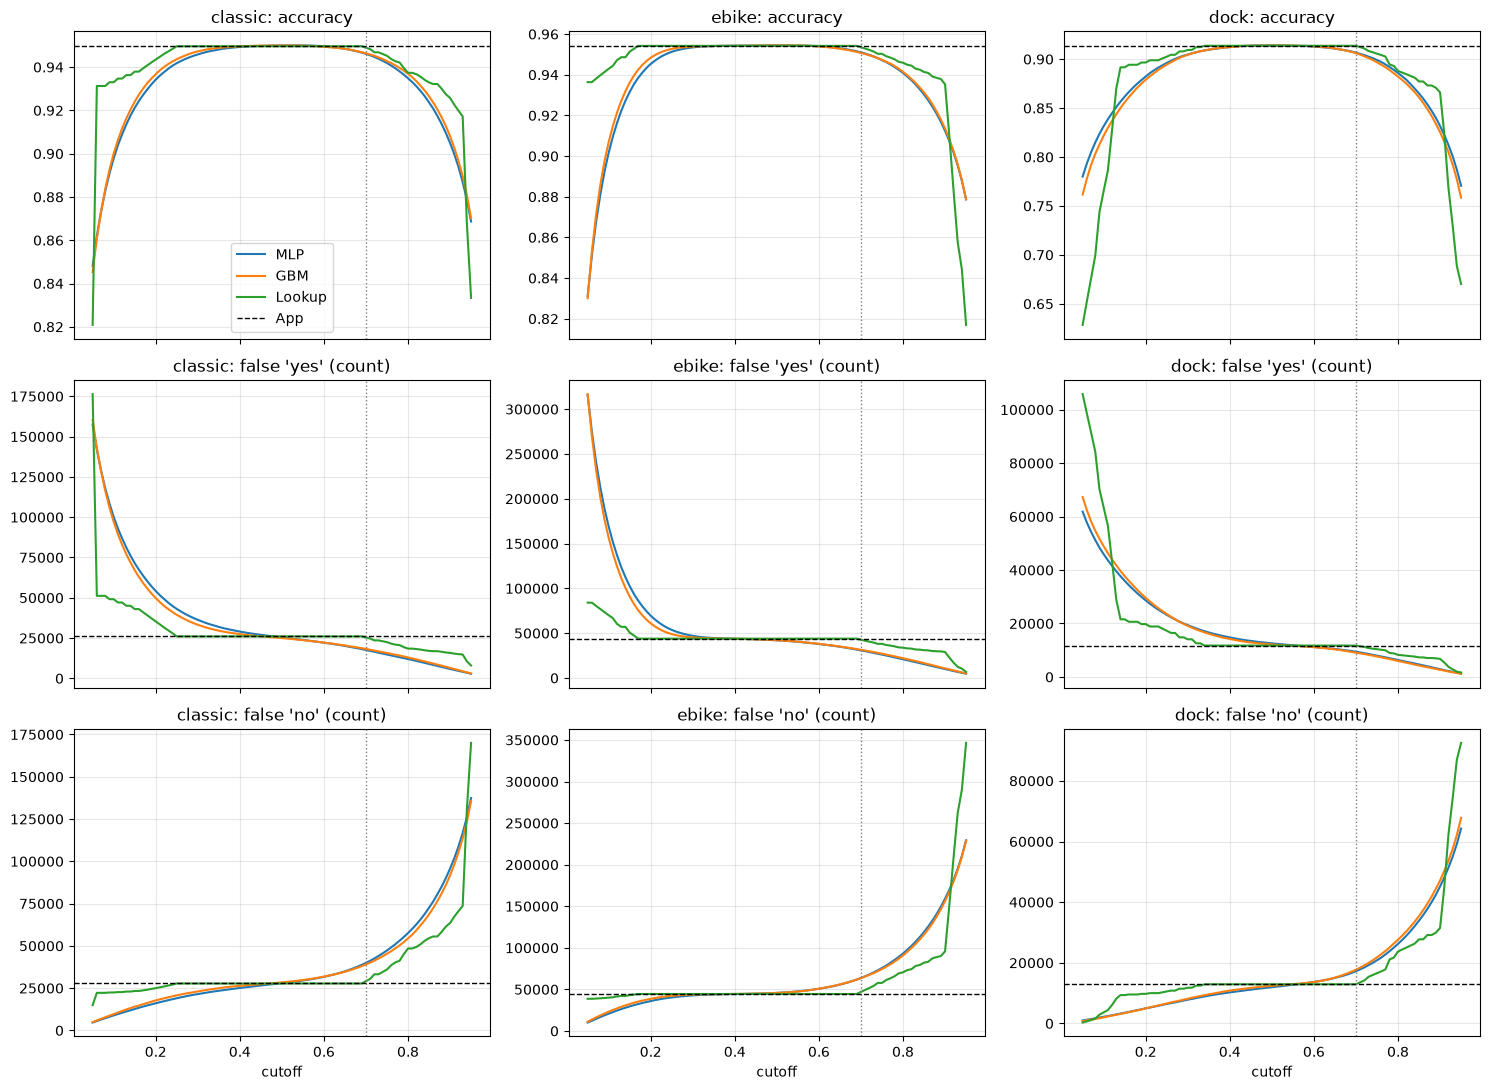

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True)
colors = {"MLP": "C0", "GBM": "C1", "Lookup": "C2"}
panels = [("accuracy", "accuracy"), ("false yes", "false 'yes' (count)"), ("false no", "false 'no' (count)")]
for col, k in enumerate(LABELS):
    for row, (metric, title) in enumerate(panels):
        ax = axes[row, col]
        for m in MODELS:
            ax.plot(SWEEP_CUTOFFS, curves[(k, m)][metric], color=colors[m], label=m)
        ax.axhline(val_app[k][metric], color="k", ls="--", lw=1, label="App")
        ax.axvline(FIXED_CUTOFF, color="grey", ls=":", lw=1)
        ax.set_title(f"{k}: {title}")
        ax.grid(alpha=0.3)
        if row == 2:
            ax.set_xlabel("cutoff")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 6. Cutoffs picked on validation

In [9]:
picked = {}
rows = []
for k in LABELS:
    for m in MODELS:
        c = curves[(k, m)]
        best = float(c.loc[c["accuracy"].idxmax(), "cutoff"])
        ok = c[c["yes wrong %"] <= val_app[k]["yes wrong %"]]
        safe = float(ok["cutoff"].min()) if len(ok) else np.nan
        picked[("best accuracy", k, m)] = best
        picked[("as safe as app", k, m)] = safe
        rows.append({"label": k, "model": m, "best accuracy": best, "as safe as app": safe,
                     "app 'yes' wrong % (val)": val_app[k]["yes wrong %"]})
display(pd.DataFrame(rows).set_index(["label", "model"]).round(2))

best accuracy  as safe as app  app 'yes' wrong % (val)
label   model                                                         
classic MLP              0.54            0.48                     5.45
        GBM              0.50            0.46                     5.45
        Lookup           0.25            0.25                     5.45
ebike   MLP              0.49            0.39                     7.29
        GBM              0.49            0.39                     7.29
        Lookup           0.17            0.17                     7.29
dock    MLP              0.50            0.56                     6.86
        GBM              0.51            0.54                     6.86
        Lookup           0.34            0.34                     6.86

## 7. All cutoffs applied to test

Hard cases first, then all rows. The app row is the same in every block.

In [10]:
all_cutoffs = {**fixed, **picked}
test_tables = {scope: score_table("test", all_cutoffs, scope) for scope in ["hard", "all"]}
for scope, t in test_tables.items():
    print(f"Test, {scope} {'cases' if scope == 'hard' else 'rows'}")
    display(t.style.format(FMT))

Test, hard cases


Test, all rows


## 8. Where does the MLP gain? (test, hard cases)

Split by the count now and by horizon. "extra correct" is MLP correct minus app correct in that group. The MLP uses its best-accuracy cutoff from validation.

In [11]:
def breakdown(split: str, model: str, cutoff_name: str) -> pd.DataFrame:
    p = preds[split]
    rows = []
    for k in LABELS:
        c = all_cutoffs[(cutoff_name, k, model)]
        hard = p[f"m_{k}"].to_numpy() == 1
        q = p.loc[hard]
        y = q[f"y_{k}"].to_numpy() == 1
        app_yes = q[f"p_app_{k}"].to_numpy() >= 0.5
        mod_yes = q[f"p_{model.lower()}_{k}"].to_numpy() >= c
        groups = {
            "count now": q[NOW_COL[k]].astype(str).to_numpy(),
            "horizon": pd.cut(q["h"], H_BINS, labels=H_NAMES).astype(str).to_numpy(),
        }
        for by, g in groups.items():
            for v in (H_NAMES if by == "horizon" else sorted(np.unique(g))):
                sel = g == v
                a, b = tally(y[sel], app_yes[sel]), tally(y[sel], mod_yes[sel])
                rows.append({"label": k, "by": by, "group": v, "queries": a["queries"],
                             "app accuracy": a["accuracy"], f"{model} accuracy": b["accuracy"],
                             "extra correct": b["correct"] - a["correct"],
                             "app false yes": a["false yes"], f"{model} false yes": b["false yes"],
                             "app false no": a["false no"], f"{model} false no": b["false no"]})
    return pd.DataFrame(rows).set_index(["label", "by", "group"])


gain = breakdown("test", "MLP", "best accuracy")
display(gain.style.format({"queries": "{:,}", "app accuracy": "{:.2%}", "MLP accuracy": "{:.2%}", "extra correct": "{:+,}",
                           "app false yes": "{:,}", "MLP false yes": "{:,}", "app false no": "{:,}", "MLP false no": "{:,}"}))

## 9. Summary (test split)

One line per label and scope (hard cases, all rows): correct answers out of all queries for the app and for the MLP at 0.7 and at its best-accuracy cutoff.

In [12]:
summary = []
for scope, t in test_tables.items():
    for k in LABELS:
        app = pick(t, k, "App")
        r = {"scope": scope, "label": k, "queries": int(app["queries"]),
             "app correct": int(app["correct"]), "app accuracy": app["accuracy"]}
        for name in ["0.7", "best accuracy"]:
            c = all_cutoffs[(name, k, "MLP")]
            row = pick(t, k, "MLP", f"{name} ({c:.2f})")
            r[f"MLP @{name} correct"] = int(row["correct"])
            r[f"MLP @{name} accuracy"] = row["accuracy"]
            r[f"MLP @{name} extra correct"] = int(row["correct"] - app["correct"])
        summary.append(r)
summary = pd.DataFrame(summary).set_index(["scope", "label"])
display(summary.style.format({c: ("{:+,}" if "extra" in c else "{:.2%}" if "accuracy" in c else "{:,}") for c in summary.columns}))

## 10. Reading the results

These notes describe the predictions saved by the last `train_model.ipynb` run. Re-check them against the tables above after retraining.

1. **As a yes/no answer, the models tie with the app.** At their best-accuracy cutoffs, the MLP and GBM are within about 0.03 percentage points of the app on every label (the MLP is slightly behind on docks: its cutoff, picked on validation, does not carry over perfectly to test). The Lookup table's best cutoff gives exactly the app's answers.
2. **Why:** the count now nearly decides the yes/no answer on its own. With 0 showing, about 96% of classic queries still had none `h` minutes later, and with 1 showing, about 93% still had one. The models rarely move a probability across the cutoff against what the count says, so they almost never change the answer (see section 8).
3. **A 0.7 cutoff loses accuracy.** It removes some false "yes" answers but adds more false "no" answers, so the MLP gets a few thousand fewer right per label than the app. It does lower the "yes" wrong %, which is worth it only if a wasted trip is much worse for the rider than skipping a station that turned out fine.
4. **The model's gain is in the probability, not the yes/no.** The Brier scores in `train_model.ipynb` are about 14-21% better than the app because the MLP knows *how sure* to be: for example, 1 bike now and 14 minutes away should get a lower chance than 2 bikes now and 3 minutes away. A yes/no answer throws that away. Showing the chance itself (or a yes / maybe / no answer) is how the model would help a rider.